In [ ]:
#EDA (Exploratory Data Analysis): Exploring banking loan data using Python, Pandas, 
#and visualization libraries to understand loan performance, customer segments, outstanding balances, and default trends.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
file_path = "Loan_Fact.xlsx"

loan = pd.read_excel(file_path, sheet_name="Loan_Fact")
customer = pd.read_excel(file_path, sheet_name="CUST")
product = pd.read_excel(file_path, sheet_name="PROD")

In [4]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [5]:
loan.head()

,ApplicationID,ApplicationDate,CustomerID,LoanID,LoanAmount,EMI,OutstandingBalance,LoanStatus,DefaultFlag,Branch
0,A0001,2024-11-21,C026,L018,231636,5386.88,115818.00,Active,0,Kolkata
1,A0002,2025-06-12,C005,L004,418258,3144.80,146390.30,Defaulted,1,Delhi
2,A0003,2024-05-08,C028,L019,208302,1310.08,72905.70,Active,0,Mumbai
3,A0004,2024-02-23,C027,L015,3744417,46227.37,561662.55,Active,0,Ahmedabad
4,A0005,2025-09-08,C014,L008,1528922,26823.19,229338.30,Active,0,Bengaluru


In [6]:
print("Dataset shape:", loan.shape)
print("Column names:", loan.columns.tolist())

Dataset shape: (150, 10)
Column names: ['ApplicationID', 'ApplicationDate', 'CustomerID', 'LoanID', 'LoanAmount', 'EMI', 'OutstandingBalance', 'LoanStatus', 'DefaultFlag', 'Branch']


In [5]:
loan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ApplicationID       150 non-null    object        
 1   ApplicationDate     150 non-null    datetime64[ns]
 2   CustomerID          150 non-null    object        
 3   LoanID              150 non-null    object        
 4   LoanAmount          150 non-null    int64         
 5   EMI                 150 non-null    float64       
 6   OutstandingBalance  150 non-null    float64       
 7   LoanStatus          150 non-null    object        
 8   DefaultFlag         150 non-null    int64         
 9   Branch              150 non-null    object        
dtypes: datetime64[ns](1), float64(2), int64(2), object(5)
memory usage: 11.8+ KB


In [7]:
# Missing values
print(loan.isnull().sum())

ApplicationID         0
ApplicationDate       0
CustomerID            0
LoanID                0
LoanAmount            0
EMI                   0
OutstandingBalance    0
LoanStatus            0
DefaultFlag           0
Branch                0
dtype: int64


In [8]:
# Duplicate rows
print("Duplicate rows:", loan.duplicated().sum())

Duplicate rows: 0


In [9]:
loan.describe()

,ApplicationDate,LoanAmount,EMI,OutstandingBalance,DefaultFlag
count,150,1.500000e+02,150.000000,1.500000e+02,150.000000
mean,2024-12-16 22:52:48,1.801422e+06,19480.051200,5.946682e+05,0.126667
min,2024-01-04 00:00:00,8.918800e+04,629.290000,0.000000e+00,0.000000
25%,2024-05-26 00:00:00,3.820000e+05,2874.660000,5.570640e+04,0.000000
50%,2024-11-30 00:00:00,7.876800e+05,6538.800000,2.136065e+05,0.000000
75%,2025-07-05 06:00:00,2.967735e+06,24156.485000,6.684438e+05,0.000000
max,2025-12-29 00:00:00,9.790569e+06,189210.080000,6.363870e+06,1.000000
std,NaN,2.078878e+06,28747.668606,9.189329e+05,0.333713


In [32]:
#Analyze loan status

In [10]:
#Check how many loans belong to each status.
loan["LoanStatus"].value_counts()

LoanStatus
Active       102
Closed        29
Defaulted     19
Name: count, dtype: int64

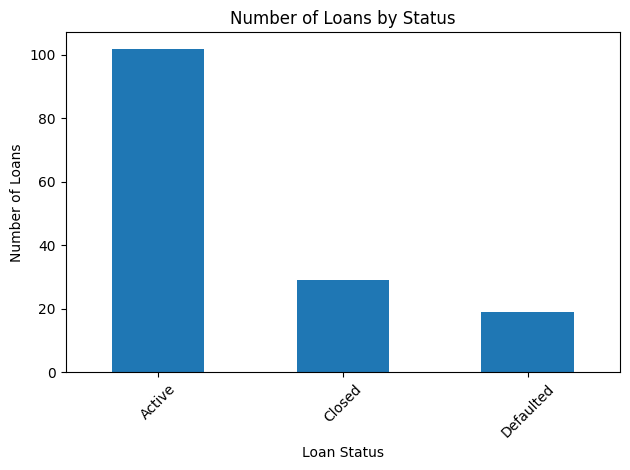

In [11]:
loan["LoanStatus"].value_counts().plot(
    kind="bar",
    title="Number of Loans by Status"
)

plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
#Analyze loan amounts
print("Total Loan Amount:", loan["LoanAmount"].sum())
print("Average Loan Amount:", loan["LoanAmount"].mean())
print("Maximum Loan Amount:", loan["LoanAmount"].max())
print("Total Outstanding Balance:", loan["OutstandingBalance"].sum())

Total Loan Amount: 270213339
Average Loan Amount: 1801422.26
Maximum Loan Amount: 9790569
Total Outstanding Balance: 89200236.19999999


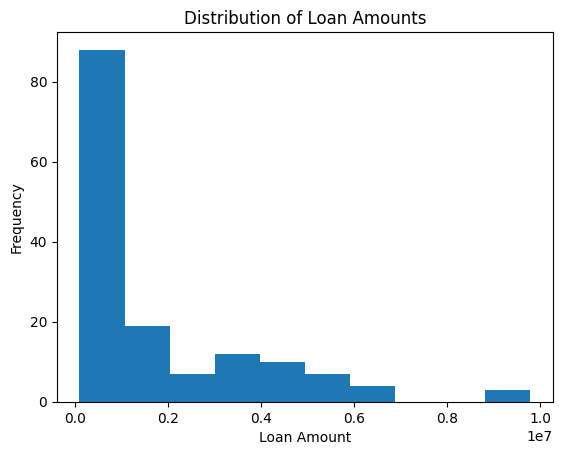

In [13]:
#Visualize loan amounts
loan["LoanAmount"].plot(
    kind="hist",
    bins=10,
    title="Distribution of Loan Amounts"
)

plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.show()

In [ ]:
#Analyze loan types

In [14]:
#combine loan data with product information if the LoanType column is in the PROD sheet.
data = pd.merge(loan, product, on="LoanID", how="left")

In [31]:
#count loans by type:
data["LoanType"].value_counts()

LoanType
Personal Loan                  26
LAP (Loan Against Property)    21
Home Loan                      19
Car Loan                       17
Credit Line Loan               17
Agriculture Loan               14
Gold Loan                      13
Education Loan                 12
Business Loan                  11
Name: count, dtype: int64

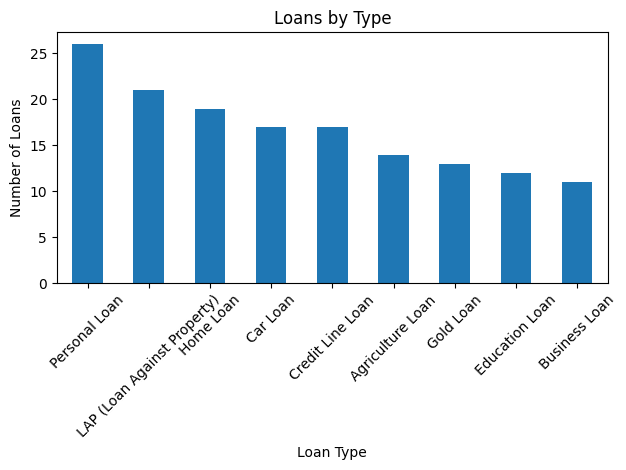

In [16]:
data["LoanType"].value_counts().plot(
    kind="bar",
    title="Loans by Type"
)

plt.xlabel("Loan Type")
plt.ylabel("Number of Loans")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
#Analyze outstanding balance by loan type

In [17]:
outstanding = data.groupby("LoanType")["OutstandingBalance"].sum()

print(outstanding)

LoanType
Agriculture Loan                4331626.15
Business Loan                  12661938.60
Car Loan                        5589920.55
Credit Line Loan                2032742.30
Education Loan                  3667357.35
Gold Loan                       1370737.75
Home Loan                      30204488.65
LAP (Loan Against Property)    23236687.75
Personal Loan                   6104737.10
Name: OutstandingBalance, dtype: float64


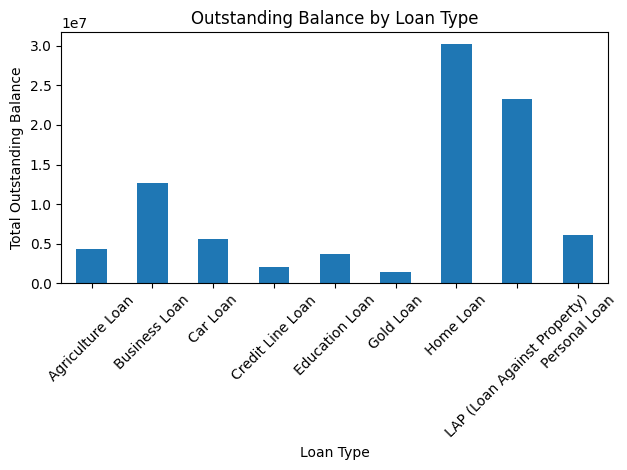

In [18]:
outstanding.plot(
    kind="bar",
    title="Outstanding Balance by Loan Type"
)

plt.xlabel("Loan Type")
plt.ylabel("Total Outstanding Balance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
#Analyze customer segments

In [19]:
#Merge the customer information with your loan data.
data = pd.merge(data, customer, on="CustomerID", how="left")

In [20]:
#Count customers by segment:
data["CustomerSegment"].value_counts()

CustomerSegment
High Value      64
Medium Value    58
Low Value       28
Name: count, dtype: int64

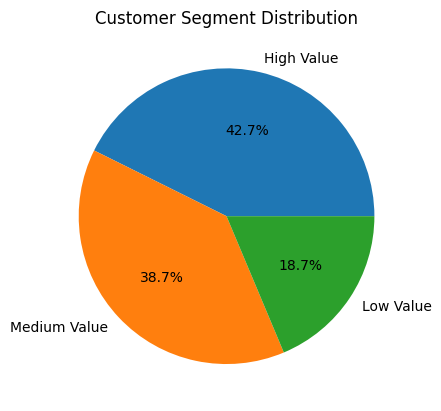

In [23]:
#Visualize the customer segments:
data["CustomerSegment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Customer Segment Distribution"
)

plt.ylabel("")
plt.show()

In [29]:
#Analyze default risk(If DefaultFlag contains 1 for default and 0 for non-default, calculate the default percentage.)

In [24]:
default_rate = data["DefaultFlag"].mean() * 100

print("Default Rate:", round(default_rate, 2), "%")

Default Rate: 12.67 %


In [30]:
#Compare defaults by loan type:

In [25]:
default_by_type = data.groupby("LoanType")["DefaultFlag"].mean() * 100

print(default_by_type)

LoanType
Agriculture Loan               14.285714
Business Loan                   9.090909
Car Loan                        5.882353
Credit Line Loan               17.647059
Education Loan                  8.333333
Gold Loan                      23.076923
Home Loan                       0.000000
LAP (Loan Against Property)     4.761905
Personal Loan                  26.923077
Name: DefaultFlag, dtype: float64


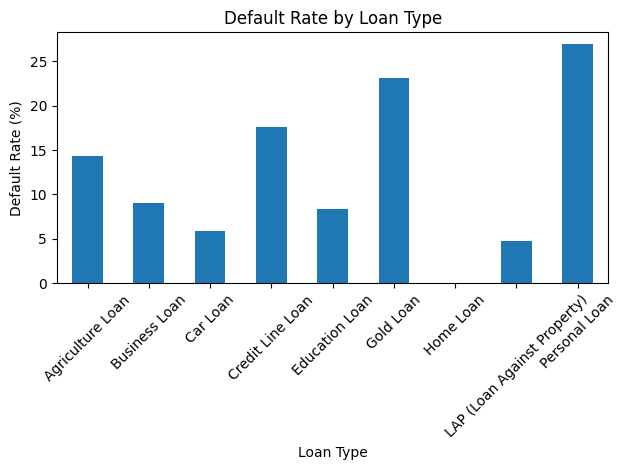

In [26]:
default_by_type.plot(
    kind="bar",
    title="Default Rate by Loan Type"
)

plt.xlabel("Loan Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()